
⏱ Training Time: 0.07 seconds

📊 Train Set Scores:
  MAE:  0.02139
  RMSE: 0.02832
  R²:   0.98785

📊 Test Set Scores:
  MAE:  0.04171
  RMSE: 0.05217
  R²:   0.95692

📉 5-Fold Cross-Validation R² Scores:
  Fold 1: R² = 0.94962
  Fold 2: R² = 0.87114
  Fold 3: R² = 0.85238
  Fold 4: R² = 0.86347
  Fold 5: R² = 0.93746

Mean R²: 0.89482
Std Dev: 0.04041


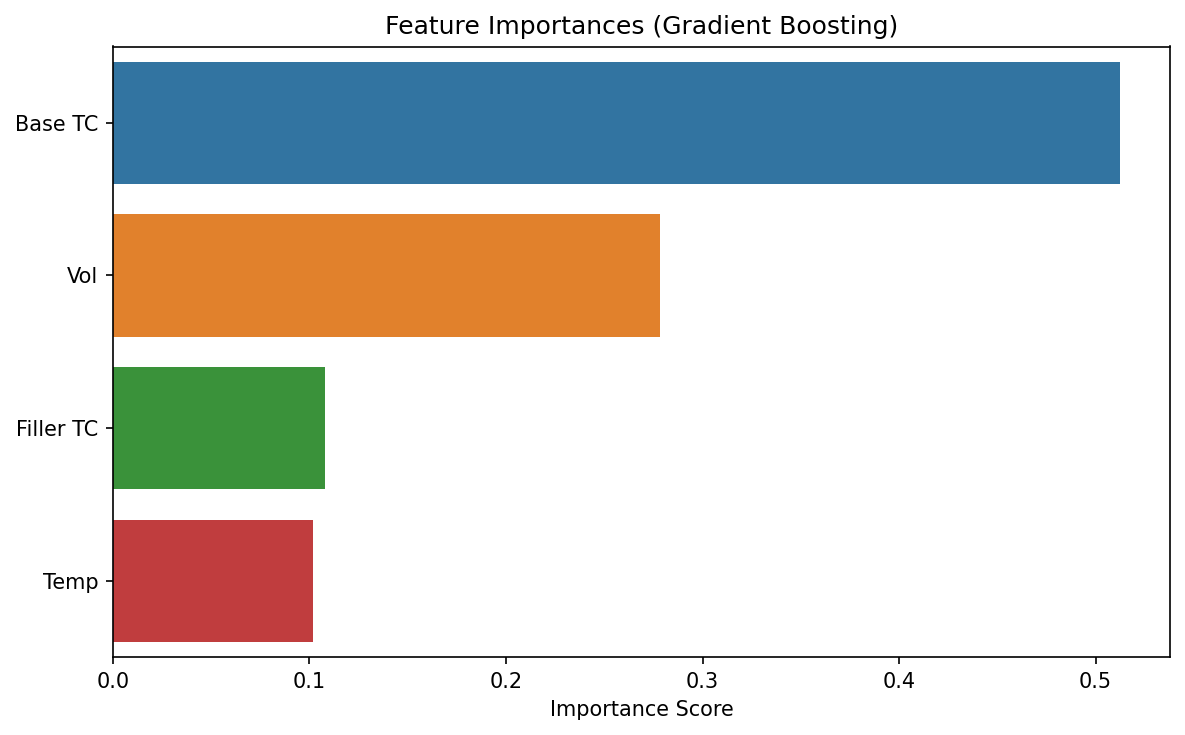


🔍 Full Test Data (20% sample):
       Base TC     Filler TC        Vol        Temp  Composite_Tc
158  0.196109     30.141845  30.028820   89.685620      0.903681
109  0.049104   2511.298205   6.948666    3.940242      0.081549
131  0.020108   1198.025794  19.872277   20.191215      0.447243
55   0.051119   2453.490408   6.977799    3.984166      0.080704
94   0.202079     30.156872  25.544664   79.202469      0.713021
29   0.020000   1200.000000  25.000000   20.000000      0.550000
101  0.200313     30.089364  30.345538   77.515145      0.846113
51   0.200000     30.000000  30.000000  100.000000      0.920000
100  0.378163  23904.402361  20.003195    7.043156      0.805426
144  0.020263   1196.953035  30.036207   19.788426      0.651453
19   0.161600      0.579000  57.000000   40.000000      0.413500
84   0.202408     30.224849  20.292375   80.335657      0.557530
15   0.100000      0.170000  60.000000  100.000000      0.300000
66   0.015354   1009.200177  20.082186    6.975431      0

C:\Users\manas\anaconda3\lib\site-packages\sklearn\base.py:450: UserWarning: X does not have valid feature names, but GradientBoostingRegressor was fitted with feature names
  warnings.warn(


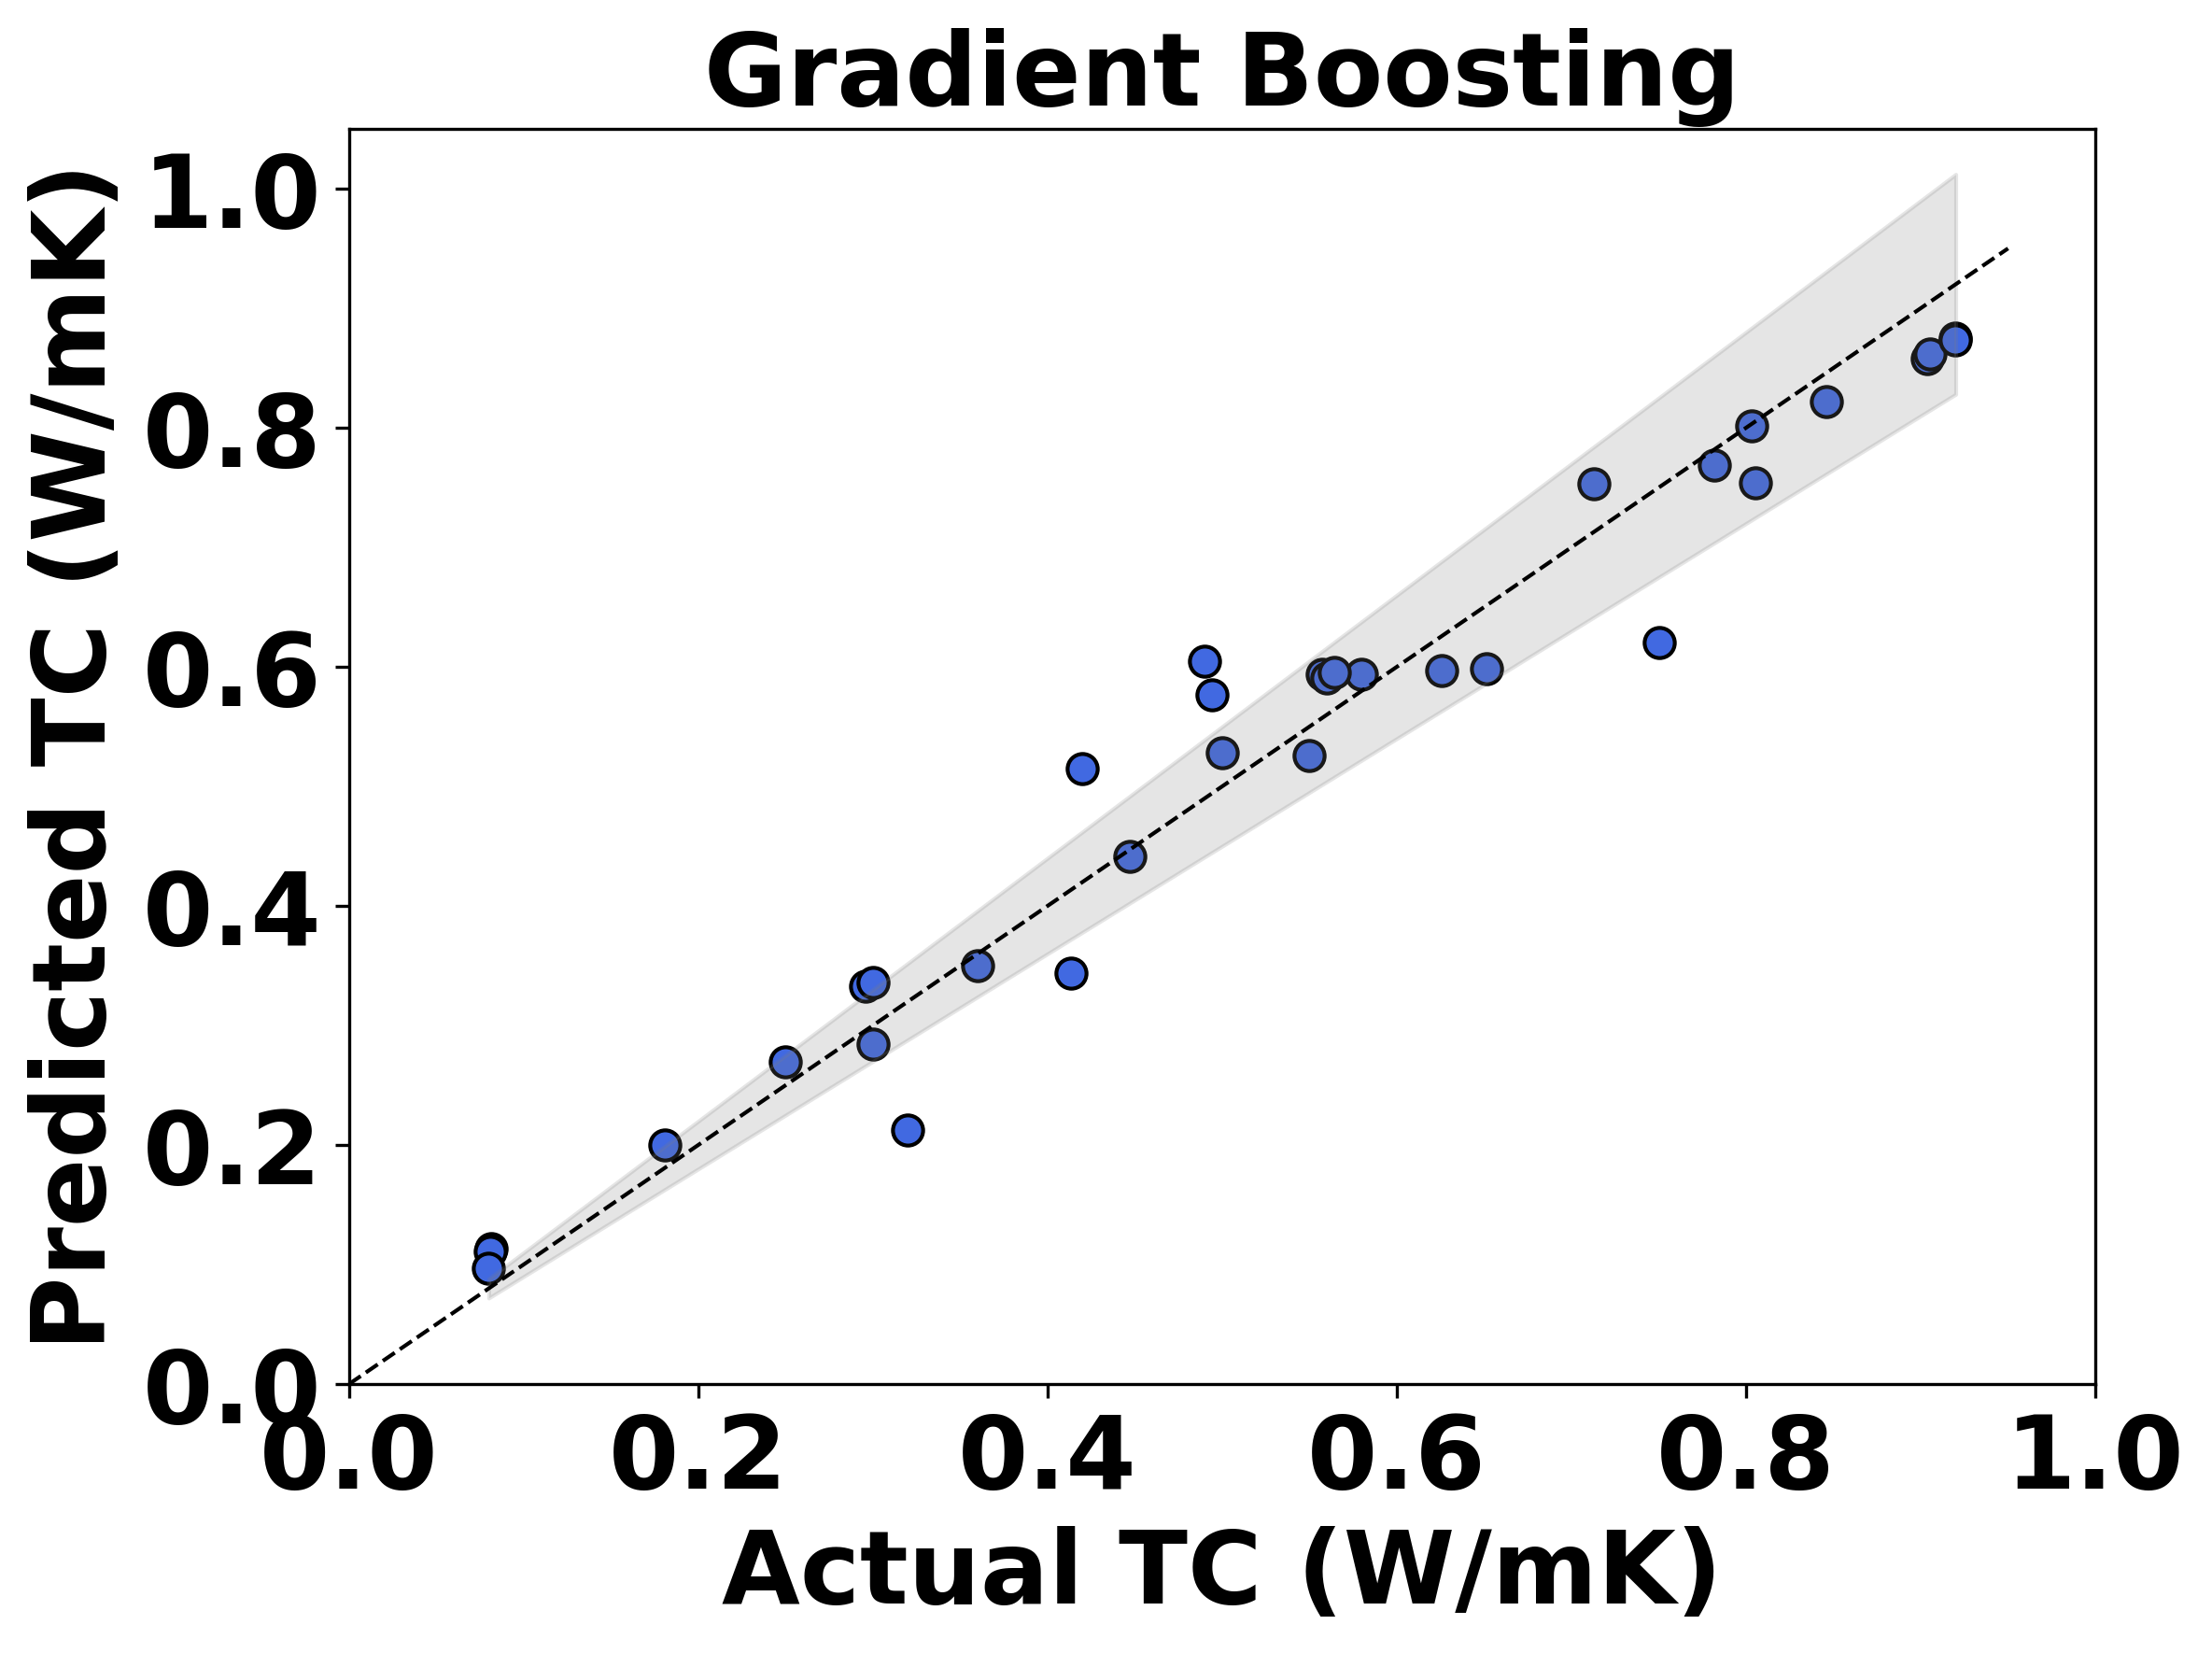

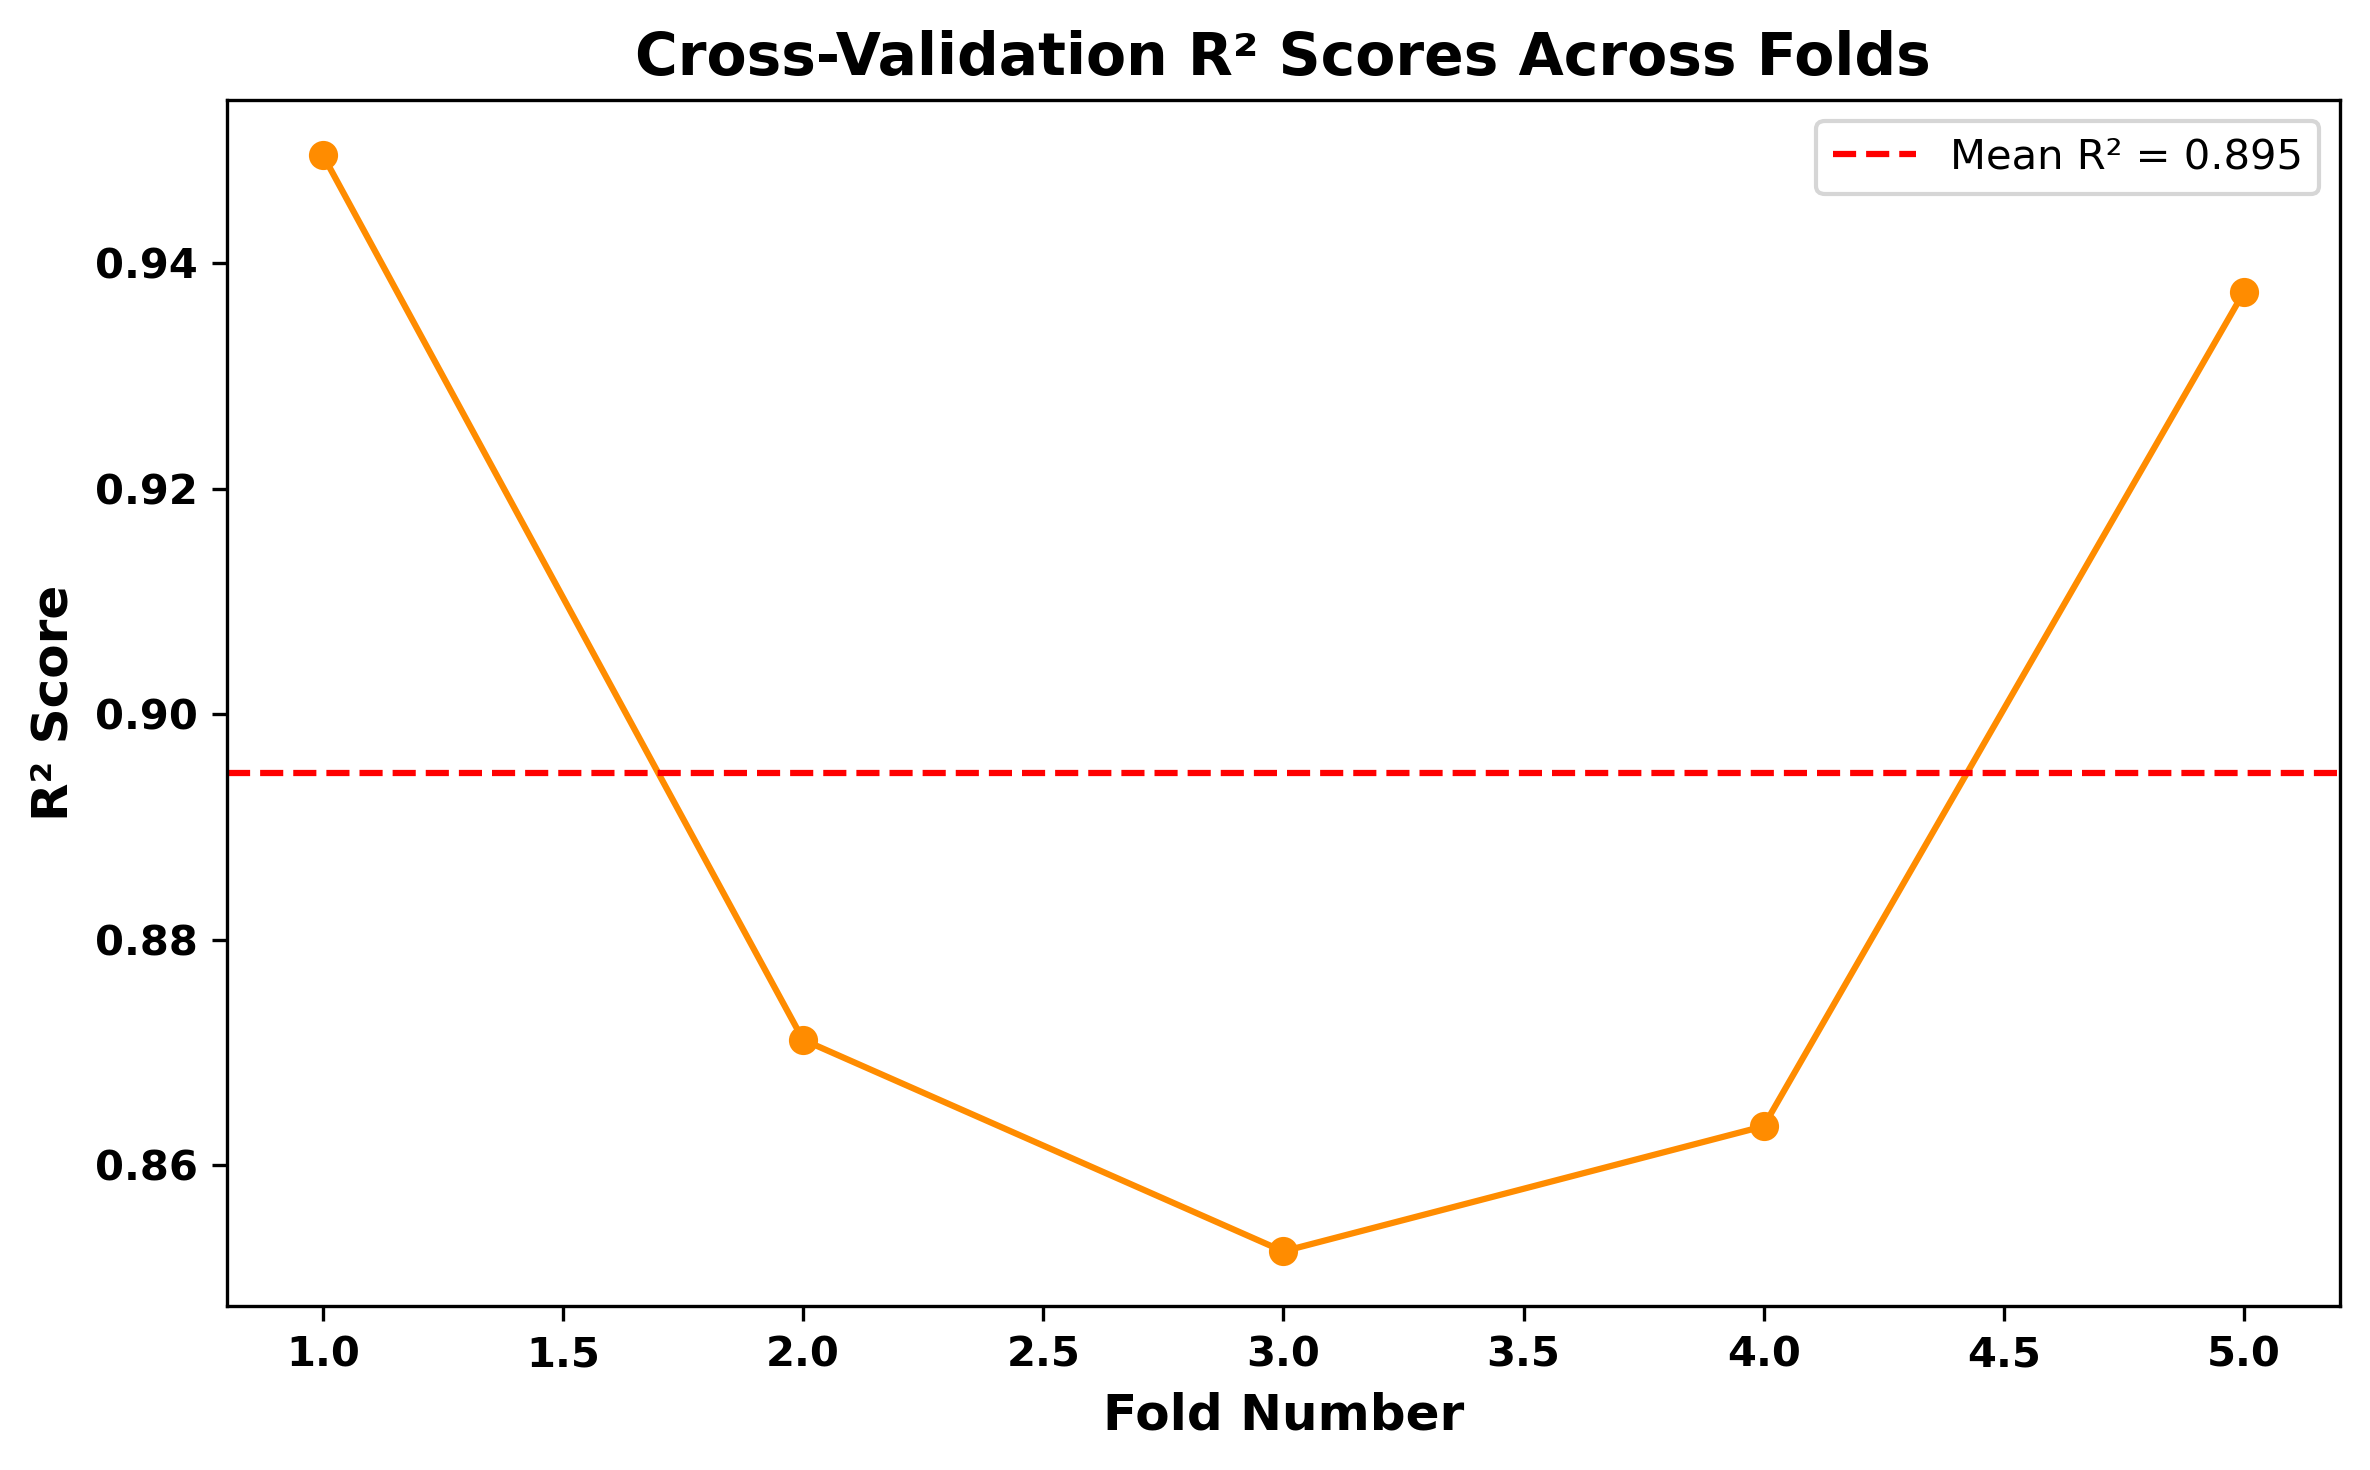

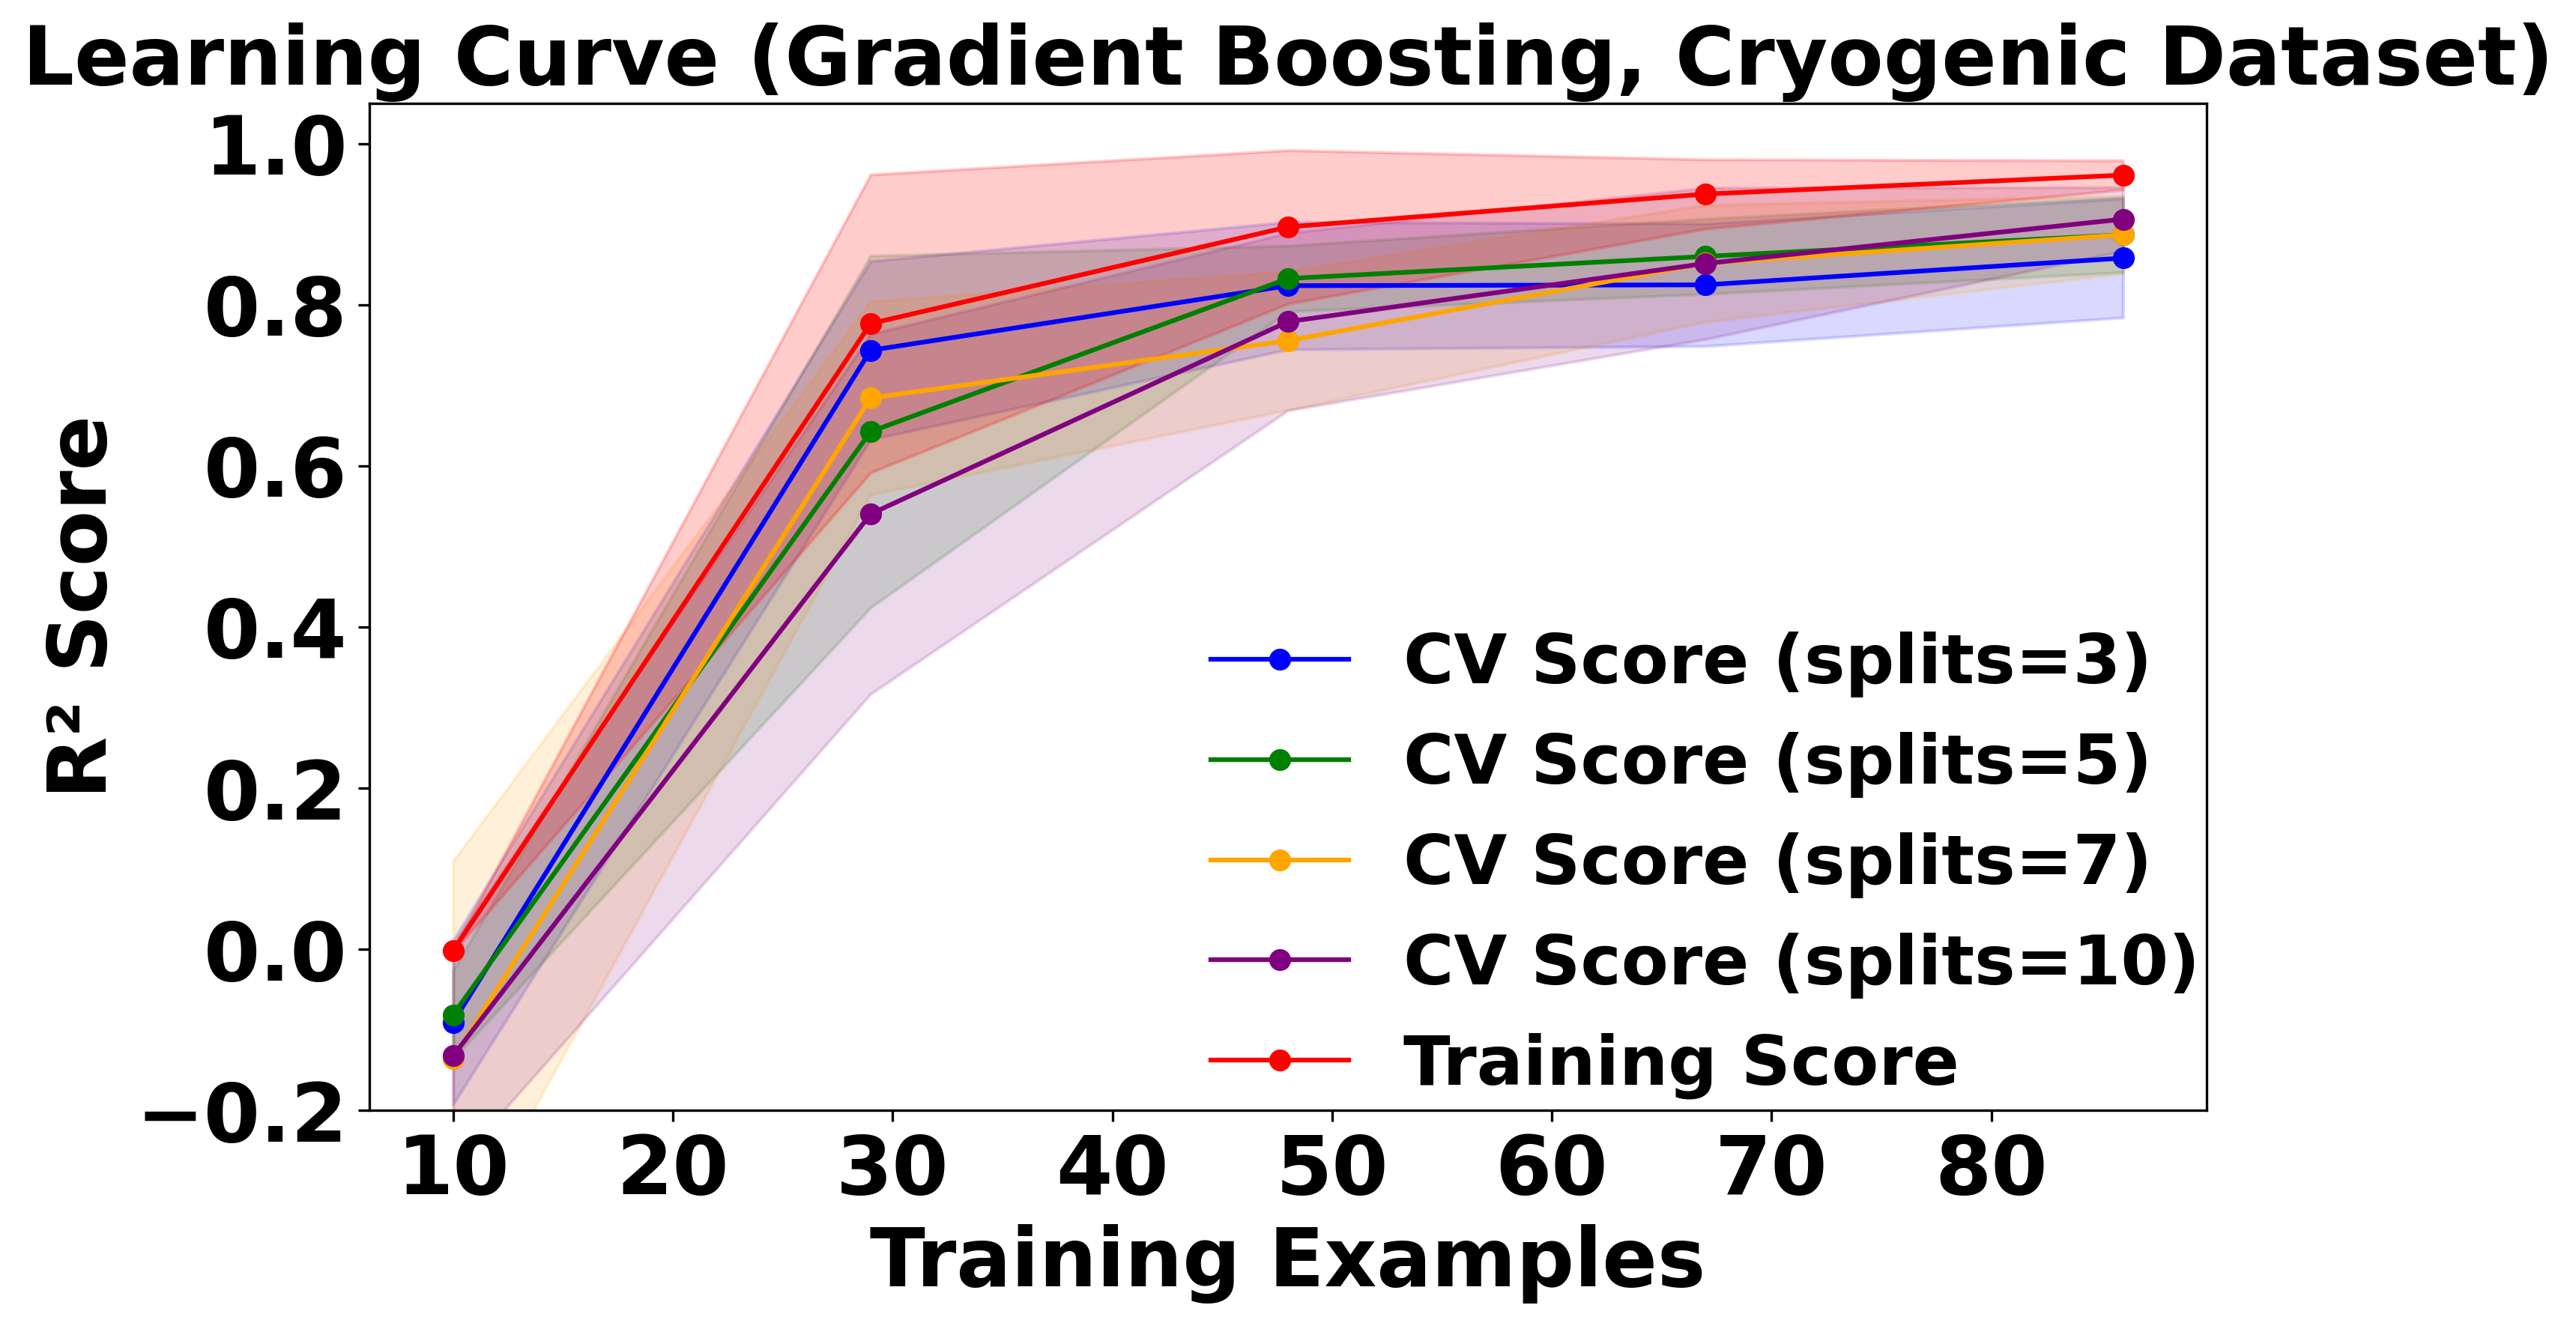

In [27]:
# 📦 Imports
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, KFold, learning_curve
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 📂 Load dataset
file_path = r'F:\Program Files (x86)\OneDrive\Desktop\ML edit 18\Cryogenic\Cryogenic_Temp_3x_Augmented_1Percent_Noise.xlsx'
df = pd.read_excel(file_path)

# 🧹 Feature & Target Split
X = df.drop(columns=["Composite TC"])
y = df["Composite TC"]

# ✂️ Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ✅ Regularised Gradient Boosting Model
model = GradientBoostingRegressor(
    n_estimators=600,
    learning_rate=0.03,
    max_depth=4,
    subsample=0.6,
    max_features='sqrt',
    min_samples_split=5,
    min_samples_leaf=3,
    validation_fraction=0.1,
    n_iter_no_change=10,
    random_state=42
)

# 🚀 Train
start = time.time()
model.fit(X_train, y_train)
end = time.time()
print(f"\n⏱ Training Time: {end - start:.2f} seconds")

# 📈 Predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# 📊 Evaluation Function
def print_scores(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred, squared=False)
    r2 = r2_score(y_true, y_pred)
    print(f"\n📊 {label} Scores:")
    print(f"  MAE:  {mae:.5f}")
    print(f"  RMSE: {rmse:.5f}")
    print(f"  R²:   {r2:.5f}")

# 🧾 Final Evaluation
print_scores(y_train, y_train_pred, "Train Set")
print_scores(y_test, y_test_pred, "Test Set")

# 🔁 5-Fold Cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='r2', n_jobs=-1)

print("\n📉 5-Fold Cross-Validation R² Scores:")
for i, score in enumerate(cv_scores, 1):
    print(f"  Fold {i}: R² = {score:.5f}")
print(f"\nMean R²: {cv_scores.mean():.5f}")
print(f"Std Dev: {cv_scores.std():.5f}")

# 📊 Feature Importance
feat_imp = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 5), dpi=150)
sns.barplot(x=feat_imp, y=feat_imp.index)
plt.title("Feature Importances (Gradient Boosting)")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()

# 🔍 Full Test Data Output
test_combined = X_test.copy()
test_combined['Composite_Tc'] = y_test
print("\n🔍 Full Test Data (20% sample):\n", test_combined)

# 🔮 Manual prediction
manual_input = [[0.35, 0.65, 15, 4.2]]
predicted_tc = model.predict(manual_input)
print(f"\n🧪 Predicted Composite TC for input {manual_input[0]}: {predicted_tc[0]:.4f}")

# 🖼️ Scatter Plot with ±10% Band
y_true = y_test.values
y_pred = y_test_pred
lower = y_true * 0.90
upper = y_true * 1.10
sorted_idx = np.argsort(y_true)

plt.figure(figsize=(8, 6), dpi=300)
plt.scatter(y_true, y_pred, color='royalblue', s=60, edgecolor='black')
plt.fill_between(np.sort(y_true), lower[sorted_idx], upper[sorted_idx], color='gray', alpha=0.2)
plt.plot([0, 0.95], [0, 0.95], 'k--', lw=1)
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.xlabel('Actual TC (W/mK)', fontsize=26, fontweight='bold')
plt.ylabel('Predicted TC (W/mK)', fontsize=26, fontweight='bold')
plt.title('Gradient Boosting', fontsize=26, fontweight='bold')
plt.locator_params(axis='x', nbins=6)
plt.locator_params(axis='y', nbins=6)
plt.xticks(fontsize=26, fontweight='bold')
plt.yticks(fontsize=26, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

# 📈 Line Plot of CV Scores
plt.figure(figsize=(8, 5), dpi=300)
plt.plot(range(1, len(cv_scores)+1), cv_scores, marker='o', linestyle='-', color='darkorange')
plt.axhline(y=cv_scores.mean(), color='red', linestyle='--', label=f'Mean R² = {cv_scores.mean():.3f}')
plt.title('Cross-Validation R² Scores Across Folds', fontsize=14, fontweight='bold')
plt.xlabel('Fold Number', fontsize=12, fontweight='bold')
plt.ylabel('R² Score', fontsize=12, fontweight='bold')
plt.xticks(fontsize=10, fontweight='bold')
plt.yticks(fontsize=10, fontweight='bold')
plt.grid(False)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

# 📚 Learning Curve
splits_list = [3, 5, 7, 10]
colors = ['blue', 'green', 'orange', 'purple']
min_allowed_size = min([int(len(X_train) * ((s - 1) / s)) for s in splits_list])
train_sizes_fixed = np.linspace(10, min_allowed_size, 5, dtype=int)

plt.figure(figsize=(10, 6), dpi=300)
for split, color in zip(splits_list, colors):
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_train, y_train,
        train_sizes=train_sizes_fixed,
        cv=KFold(n_splits=split, shuffle=True, random_state=42),
        scoring='r2',
        n_jobs=-1
    )
    val_mean = np.mean(val_scores, axis=1)
    val_std = np.std(val_scores, axis=1)
    plt.plot(train_sizes, val_mean, marker='o', label=f'CV Score (splits={split})', color=color)
    plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, color=color, alpha=0.15)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
plt.plot(train_sizes, train_mean, marker='o', color='red', label='Training Score')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, color='red', alpha=0.2)

plt.title('Learning Curve (Gradient Boosting, Cryogenic Dataset)', fontsize=26, fontweight='bold')
plt.xlabel('Training Examples', fontsize=26, fontweight='bold')
plt.ylabel('R² Score', fontsize=26, fontweight='bold')
plt.legend(loc='lower right', bbox_to_anchor=(1.03, -0.05), prop={'weight': 'bold', 'size': 22}, frameon=False)
plt.xticks(fontsize=26, fontweight='bold')
plt.yticks(fontsize=26, fontweight='bold')
plt.ylim(-0.2, 1.05)
plt.grid(False)
plt.tight_layout()
plt.show()
